# The world's smallest transformer model

This code accompanies the YouTube video [The world's smallest transformer](https://www.youtube.com/watch?v=3ZxbaeqZIHQ)

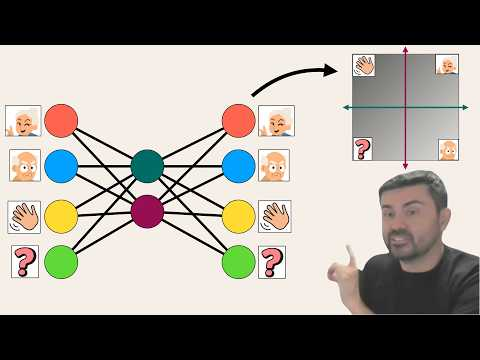

In [1]:
from IPython.display import YouTubeVideo
YouTubeVideo('3ZxbaeqZIHQ', width=800, height=450)

# Training and plotting function
This function trains the transformer and creates an animation through the epochs of the embedding (first layer) and the directions (second layer).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.animation as animation
from IPython.display import HTML

def animate_network(
    sentences,
    epochs=800,
    lr=0.05,
    snap_freq=8,
    custom_colors=None,
):
    """
    Train a tiny next-word neural network on the given sentences and animate:
      Top-left  : word positions in embedding space  (columns of W₁)
      Top-right : prediction arrows                  (rows of W₂)
      Bottom    : loss curve drawn left-to-right in real time
    """

    # ── Color palette ─────────────────────────────────────────────────────
    if custom_colors is None:
        custom_colors = {
            "Mary":    "tomato",
            "Bob":     "dodgerblue",
            "greeted": "limegreen",
            "ignored": "gold",
        }
    _fallback_palette = iter(["orange", "violet", "cyan", "magenta", "coral", "white"])

    # ── Vocabulary ────────────────────────────────────────────────────────
    vocab       = sorted(set(w for s in sentences for w in s))
    w2i         = {w: i for i, w in enumerate(vocab)}
    V           = len(vocab)
    word_colors = [custom_colors.get(w, next(_fallback_palette, "white")) for w in vocab]

    pairs = [
        (w2i[s[i]], w2i[s[i + 1]])
        for s in sentences
        for i in range(len(s) - 1)
    ]

    print(f"Vocabulary ({V} words): {vocab}")
    print(f"Training pairs: {[(vocab[x], vocab[y]) for x, y in pairs]}")

    # ── Weights ───────────────────────────────────────────────────────────
    EMBED_DIM = 2
    np.random.seed(42)
    W1 = np.random.randn(EMBED_DIM, V) * 0.5   # columns = word embeddings
    W2 = np.random.randn(V, EMBED_DIM) * 0.5   # rows    = prediction directions

    def softmax(z):
        e = np.exp(z - z.max())
        return e / e.sum()

    def train_one_epoch():
        nonlocal W1, W2
        total_loss = 0.0
        for xi, yi in pairs:
            x_vec       = np.zeros(V);  x_vec[xi] = 1.0
            h           = W1 @ x_vec
            logits      = W2 @ h
            probs       = softmax(logits)
            total_loss += -np.log(probs[yi] + 1e-12)

            d_logits    = probs.copy();  d_logits[yi] -= 1.0
            dW2         = np.outer(d_logits, h)
            d_h         = W2.T @ d_logits   # uses W2 before its update
            dW1         = np.outer(d_h, x_vec)

            W2 -= lr * dW2
            W1 -= lr * dW1

        return total_loss / len(pairs)

    # ── Train and capture snapshots ───────────────────────────────────────
    snapshots = []
    for ep in range(epochs):
        loss = train_one_epoch()
        if ep % snap_freq == 0:
            snapshots.append((W1.copy(), W2.copy(), loss, ep))

    print(f"\nTraining done — {len(snapshots)} frames captured.")
    print(f"Final loss: {snapshots[-1][2]:.4f}")

    # ── Pre-compute axis limits ───────────────────────────────────────────
    all_emb   = np.array([s[0].T for s in snapshots])
    all_pred  = np.array([s[1]   for s in snapshots])
    all_loss  = np.array([s[2]   for s in snapshots])
    all_epoch = np.array([s[3]   for s in snapshots])

    def padded(data, pad=0.30):
        lo, hi = float(data.min()), float(data.max())
        return lo - max(hi - lo, 1.0) * pad, hi + max(hi - lo, 1.0) * pad

    E_xlim, E_ylim = padded(all_emb[:, :, 0]),  padded(all_emb[:, :, 1])
    P_xlim, P_ylim = padded(all_pred[:, :, 0]), padded(all_pred[:, :, 1])

    # Loss axis: x spans the full epoch range, y spans the full loss range
    loss_xlim = (0, epochs - 1)
    loss_ylim = (
        max(0, float(all_loss.min()) * 0.85),
        float(all_loss.max()) * 1.10
    )

    # ── Figure layout ─────────────────────────────────────────────────────
    # Two rows: top row holds the two spatial panels (equal width),
    # bottom row holds the loss curve spanning the full width.
    # height_ratios keeps the loss panel shorter so it feels like a footer.
    BG, PANEL = "#111118", "#1c1c2e"

    fig = plt.figure(figsize=(14, 9))
    gs  = gridspec.GridSpec(
        2, 2,
        figure=fig,
        height_ratios=[2.8, 1],   # top panels taller, loss panel shorter
        hspace=0.38,
        wspace=0.28
    )

    ax_E = fig.add_subplot(gs[0, 0])   # top-left:  embedding
    ax_P = fig.add_subplot(gs[0, 1])   # top-right: predictions
    ax_L = fig.add_subplot(gs[1, :])   # bottom:    loss curve (spans both columns)

    fig.patch.set_facecolor(BG)

    # Style the three panels consistently
    for ax, title_str in [
        (ax_E, "Embedding Space  (columns of W₁)"),
        (ax_P, "Prediction Directions  (rows of W₂)"),
        (ax_L, "Training Loss"),
    ]:
        ax.set_facecolor(PANEL)
        ax.set_title(title_str, color="white", fontsize=11, pad=8)
        ax.tick_params(colors="#666677")
        for sp in ax.spines.values():
            sp.set_edgecolor("#333344")
        ax.grid(True, color="#22223a", linewidth=0.5, zorder=0)

    ax_E.axhline(0, color="#3a3a55", lw=0.9, zorder=1)
    ax_E.axvline(0, color="#3a3a55", lw=0.9, zorder=1)
    ax_P.axhline(0, color="#3a3a55", lw=0.9, zorder=1)
    ax_P.axvline(0, color="#3a3a55", lw=0.9, zorder=1)

    # Loss panel axis labels
    ax_L.set_xlabel("Epoch", color="#888899", fontsize=9)
    ax_L.set_ylabel("Loss",  color="#888899", fontsize=9)
    ax_L.set_xlim(loss_xlim)
    ax_L.set_ylim(loss_ylim)

    suptitle = fig.suptitle("", color="white", fontsize=13)

    ax_E.set_xlim(E_xlim);  ax_E.set_ylim(E_ylim)
    ax_P.set_xlim(P_xlim);  ax_P.set_ylim(P_ylim)

    # ── Embedding panel: dots and labels ──────────────────────────────────
    W1_0, W2_0 = snapshots[0][:2]
    emb_0      = W1_0.T

    dots     = [ax_E.plot(emb_0[i, 0], emb_0[i, 1], "o",
                          color=word_colors[i], ms=13, zorder=5)[0] for i in range(V)]
    e_labels = [ax_E.text(emb_0[i, 0], emb_0[i, 1], "  " + vocab[i],
                          color=word_colors[i], fontsize=9, va="center", zorder=6) for i in range(V)]

    # ── Prediction panel: quiver arrows and labels ────────────────────────
    def make_quiver(ax, W2_s):
        return ax.quiver(
            np.zeros(V), np.zeros(V), W2_s[:, 0], W2_s[:, 1],
            color=word_colors,
            angles="xy", scale_units="xy", scale=1,
            width=0.013, headwidth=5, headlength=6, zorder=5
        )

    quiv_ref = [make_quiver(ax_P, W2_0)]
    p_labels = [ax_P.text(W2_0[i, 0], W2_0[i, 1], "  " + vocab[i],
                          color=word_colors[i], fontsize=9, va="center", zorder=6) for i in range(V)]

    # ── Loss panel: an empty line that grows each frame ───────────────────
    # We start with an empty line and reveal more data points each update.
    # The dot marker shows exactly where we are on the curve right now.
    loss_line, = ax_L.plot([], [], color="#7ec8e3", lw=2,   zorder=3)
    loss_dot,  = ax_L.plot([], [], "o", color="white", ms=6, zorder=4)

    # ── Animation update ──────────────────────────────────────────────────
    def update(frame):
        W1_s, W2_s, loss, epoch = snapshots[frame]
        suptitle.set_text(f"Epoch {epoch:4d}   |   Loss = {loss:.4f}")

        # Update embedding dots
        emb = W1_s.T
        for i in range(V):
            dots[i].set_data([emb[i, 0]], [emb[i, 1]])
            e_labels[i].set_position((emb[i, 0], emb[i, 1]))

        # Replace quiver arrows
        quiv_ref[0].remove()
        quiv_ref[0] = make_quiver(ax_P, W2_s)
        for i in range(V):
            p_labels[i].set_position((W2_s[i, 0], W2_s[i, 1]))

        # Extend loss curve up to (and including) the current frame
        xs = all_epoch[: frame + 1]
        ys = all_loss[: frame + 1]
        loss_line.set_data(xs, ys)
        loss_dot.set_data([xs[-1]], [ys[-1]])   # moving dot at the frontier

    anim = animation.FuncAnimation(
        fig, update, frames=len(snapshots), interval=80, blit=False
    )

    plt.close(fig)   # prevents a static duplicate from appearing in the notebook
    return HTML(anim.to_jshtml())

In [3]:
sentences = [
    ["Mary",    "greeted", "Bob"],
    ["Bob",     "ignored", "Mary"],
]

fig = animate_network(sentences, epochs=400, snap_freq=1, lr=0.02)
fig

Vocabulary (4 words): ['Bob', 'Mary', 'greeted', 'ignored']
Training pairs: [('Mary', 'greeted'), ('greeted', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary')]

Training done — 400 frames captured.
Final loss: 0.0228


In [4]:
sentences = [
    ["Mary",    "greeted", "Bob"],
    ["Bob",     "ignored", "Mary"],
    ["Mary",    "greeted", "Bob"],
    ["Mary",    "ignored", "Bob"], # For a change
    ["Bob",     "ignored", "Mary"],
    ["Bob",     "greeted", "Mary"], # For a change
    ["Mary",    "greeted", "Bob"],
    ["Bob",     "ignored", "Mary"],
]

animate_network(sentences)

Vocabulary (4 words): ['Bob', 'Mary', 'greeted', 'ignored']
Training pairs: [('Mary', 'greeted'), ('greeted', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary'), ('Mary', 'greeted'), ('greeted', 'Bob'), ('Mary', 'ignored'), ('ignored', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary'), ('Bob', 'greeted'), ('greeted', 'Mary'), ('Mary', 'greeted'), ('greeted', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary')]

Training done — 100 frames captured.
Final loss: 0.5940


In [5]:
sentences = [
    ["Mary",    "greeted",    "Bob"],
    ["Bob",     "ignored",    "Mary"],
    ["Mary",    "greeted",    "Carlos"],
    ["Bob",     "ignored",    "Carlos"],
    ["Carlos",  "greeted",    "Bob"],
    ["Carlos",  "ignored",    "Mary"],
]

animate_network(sentences)

Vocabulary (5 words): ['Bob', 'Carlos', 'Mary', 'greeted', 'ignored']
Training pairs: [('Mary', 'greeted'), ('greeted', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary'), ('Mary', 'greeted'), ('greeted', 'Carlos'), ('Bob', 'ignored'), ('ignored', 'Carlos'), ('Carlos', 'greeted'), ('greeted', 'Bob'), ('Carlos', 'ignored'), ('ignored', 'Mary')]

Training done — 100 frames captured.
Final loss: 0.4851


In [6]:
sentences = [
    ["Mary",    "greeted", "Bob"],
    ["Bob",     "ignored", "Mary"],
    ["Mary",    "saw",     "Bob"],
    ["Bob",     "saw",     "Mary"],
]

animate_network(sentences)

Vocabulary (5 words): ['Bob', 'Mary', 'greeted', 'ignored', 'saw']
Training pairs: [('Mary', 'greeted'), ('greeted', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary'), ('Mary', 'saw'), ('saw', 'Bob'), ('Bob', 'saw'), ('saw', 'Mary')]

Training done — 100 frames captured.
Final loss: 0.5851


In [8]:
sentences = [
    ["Mary",    "greeted",    "Bob"],
    ["Bob",     "ignored",    "Mary"],
    ["Mary",    "saw",        "Bob"],
    ["Bob",     "saw",        "Mary"],
    ["Mary",    "greeted",    "Carlos"],
    ["Bob",     "ignored",    "Carlos"],
    ["Carlos",  "greeted",    "Bob"],
    ["Carlos",  "ignored",    "Mary"],
    ["Mary",    "saw",        "Carlos"],
    ["Bob",     "saw",        "Carlos"],
    ["Carlos",  "saw",        "Bob"],
    ["Carlos",  "saw",        "Mary"],
]
animate_network(sentences)

Vocabulary (6 words): ['Bob', 'Carlos', 'Mary', 'greeted', 'ignored', 'saw']
Training pairs: [('Mary', 'greeted'), ('greeted', 'Bob'), ('Bob', 'ignored'), ('ignored', 'Mary'), ('Mary', 'saw'), ('saw', 'Bob'), ('Bob', 'saw'), ('saw', 'Mary'), ('Mary', 'greeted'), ('greeted', 'Carlos'), ('Bob', 'ignored'), ('ignored', 'Carlos'), ('Carlos', 'greeted'), ('greeted', 'Bob'), ('Carlos', 'ignored'), ('ignored', 'Mary'), ('Mary', 'saw'), ('saw', 'Carlos'), ('Bob', 'saw'), ('saw', 'Carlos'), ('Carlos', 'saw'), ('saw', 'Bob'), ('Carlos', 'saw'), ('saw', 'Mary')]

Training done — 100 frames captured.
Final loss: 0.9165
